# From One Neuron to a Transformer

**A short, hands-on workshop · GDG AI for Science**

*Companion to the talk* **Inside the Black Box: How AI Really Works**. *For more depth, the 90-minute version lives in [`../workshop/`](../workshop/).*

> ⏱️ **Teaching:** 40 min · **Exercises:** 20 min
>
> ❓ **Questions**
> - How does one artificial neuron make a decision, and how does it *learn*?
> - Why do we need *layers* of neurons, and why must they *bend*?
> - What is *attention*, and how do neurons and attention add up to a Transformer?
>
> 🎯 **Objectives**
> - Build and train a single neuron from scratch with NumPy.
> - Train a neural network with PyTorch, letting *autograd* do the calculus.
> - Write causal self-attention by hand, then swap in PyTorch's built-in version.
> - Build, train and look inside a 100,000-weight Transformer that writes DNA.

### How this notebook works

- **Run the cells in order** with **Shift + Enter** (or the ▶ button). Everything runs on a laptop CPU in about a minute.
- **🧪 Challenges** are short experiments. Have a go first, then open **💡 Solution**.
- **✅ Checkpoints** tell you what you should be seeing.
- **One idea at a time.** We write each idea from scratch *once*, then hand it to a library that does the same job, so the code stays small while the model grows:

| Part | We build | From scratch | Then the library does it |
|:--|:--|:--|:--|
| 1 | One neuron | a weighted vote, gradient descent | (NumPy only) |
| 2 | A neural network | a layer as a matrix, the chain rule | `autograd`, `nn.Linear`, `nn.Sequential`, `optim.Adam` |
| 3 | Attention | queries, keys, values and a causal mask | `F.scaled_dot_product_attention` |
| 4 | A Transformer | attention + MLP + residual connections | `nn.MultiheadAttention`, `nn.LayerNorm` |

> 📌 Like the [CAITG AI Winter School](https://gdgaiforscience.github.io/CAITG-WinterSchool/) sessions, we skip error handling and style niceties so the ideas stay in view.

### Setup

Run the next two cells. The first loads the libraries (all preinstalled on Google Colab); the second, folded away, defines two plotting helpers.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.datasets import load_iris, make_moons
from ipywidgets import interact

torch.manual_seed(0)              # the same "random" numbers for everyone
torch.__version__

'2.11.0+cu130'

In [2]:
# @title Plotting helpers (run me; reading is optional)
from matplotlib.colors import LinearSegmentedColormap

BLUE, RED, DARK_BLUE, DARK_RED = "#4285F4", "#EA4335", "#174EA6", "#A50E0E"
VOTE = LinearSegmentedColormap.from_list("vote", ["#D2E3FC", "#FFFFFF", "#FAD2CF"])
HEAT = LinearSegmentedColormap.from_list("heat", ["#FFFFFF", "#D2E3FC", BLUE, DARK_BLUE])
plt.rcParams.update({"figure.figsize": (5, 4), "axes.spines.top": False, "axes.spines.right": False})


def prob(model, X):
    """Probability of class 1, from a NumPy function or a PyTorch model."""
    if isinstance(model, nn.Module):
        return torch.sigmoid(model(torch.tensor(X, dtype=torch.float32))).detach().numpy().ravel()
    return model(X)


def plot_boundary(model, X, y):
    """Shade the plane by the model's vote. Blue circles: class 0. Red squares: class 1."""
    X, y = np.asarray(X), np.asarray(y)
    lo, hi = X.min(0) - 0.5, X.max(0) + 0.5
    g0, g1 = np.meshgrid(np.linspace(lo[0], hi[0], 200), np.linspace(lo[1], hi[1], 200))
    p = prob(model, np.c_[g0.ravel(), g1.ravel()]).reshape(g0.shape)
    plt.contourf(g0, g1, p, levels=np.linspace(0, 1, 11), cmap=VOTE)
    plt.contour(g0, g1, p, levels=[0.5], colors="#202124", linewidths=2)
    plt.scatter(*X[y == 0].T, c=BLUE, edgecolors=DARK_BLUE, marker="o")
    plt.scatter(*X[y == 1].T, c=RED, edgecolors=DARK_RED, marker="s")
    plt.title(f"accuracy: {np.mean((prob(model, X) > 0.5) == y):.0%}")
    plt.show()


def plot_attention(weights, tokens):
    """Each row is a token; the colours show where it looks."""
    plt.imshow(weights.detach(), cmap=HEAT, vmin=0, vmax=1)
    plt.xticks(range(len(tokens)), tokens, rotation=90)
    plt.yticks(range(len(tokens)), tokens)
    plt.xlabel("looks at")
    plt.ylabel("token")
    plt.colorbar(label="attention weight")
    plt.show()

---
## Part 1 · One neuron

> ⏱️ **Teaching:** 8 min · **Exercises:** 4 min
>
> ❓ How does a single neuron turn numbers into a decision? How does it learn?
>
> 🎯 Compute a neuron by hand · tune one with sliders · let gradient descent tune it for you

An artificial neuron is a **weighted vote**: multiply each input by a weight, add them up with a bias, then squash the total through an S-shaped **bend**, the sigmoid $\sigma$, to get a number between 0 and 1.

![Left: three inputs 0.9, 0.2 and 0.6 are multiplied by weights +1.2, −0.8 and +0.5, summed with a bias of −0.2 to give 1.02, and bent by a sigmoid into 0.73. Right: four such neurons stacked as the rows of a 4 by 3 matrix W; W times x plus b, bent by σ, gives 0.73, 0.58, 0.57 and 0.33.](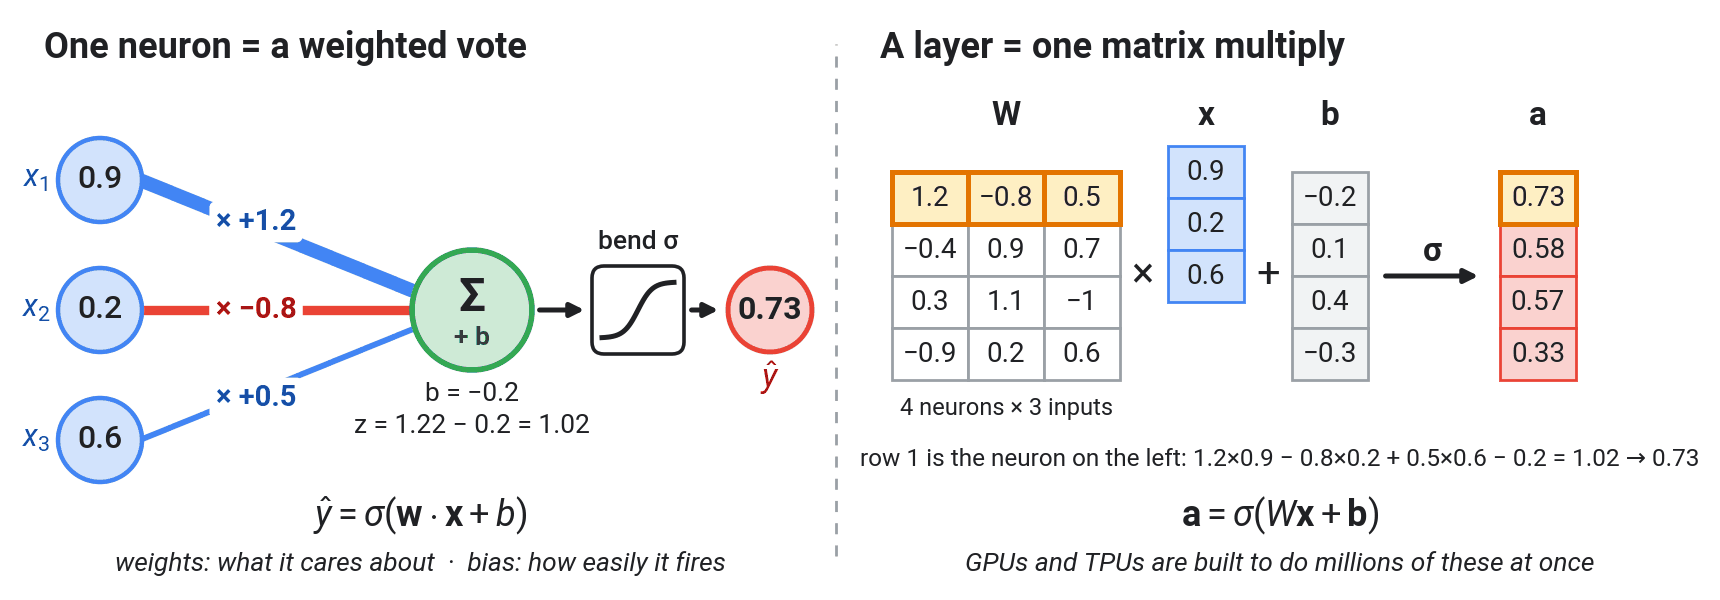)

*Picture first: the neuron from the talk (left) and a whole layer of them (right, used in Part 2).*

In [3]:
x = np.array([0.9, 0.2, 0.6])    # three inputs
w = np.array([1.2, -0.8, 0.5])   # three weights: what the neuron cares about
b = -0.2                         # bias: how easily it fires

def sigmoid(z):
    return 1 / (1 + np.exp(-z))  # the bend: squashes any number into (0, 1)

z = w @ x + b                    # the weighted vote: 1.08 - 0.16 + 0.30 - 0.20
print(z.round(2), sigmoid(z).round(2))

1.02 0.73


That's the first equation of the talk: $\hat{y} = \sigma(\mathbf{w}\cdot\mathbf{x} + b)$. The `@` sign is NumPy's dot product, the same multiply-and-add that GPUs and TPUs do trillions of times a second.

> 🧪 **Challenge 1.1 · Predict, then run**
>
> If every input is `0`, what will the neuron output? Write down a guess, then set `x = np.zeros(3)` and re-run the cell.

<details><summary><b>💡 Solution</b></summary>

With no inputs the vote is just the bias, $z = b = -0.2$, so the output is $\sigma(-0.2) \approx 0.45$. With no evidence either way, **the bias alone** decides how eagerly the neuron fires.

</details>

### A real question: which iris is it?

Fisher's iris flowers (1936) are a classic. Can one neuron tell *Iris versicolor* from *Iris virginica* using just two petal measurements?

In [4]:
iris = load_iris()
keep = iris.target > 0                       # versicolor (1) and virginica (2)
X = iris.data[keep][:, 2:]                   # inputs: petal length and petal width
y = (iris.target[keep] == 2).astype(float)   # answers: 1 = virginica, 0 = versicolor
X = (X - X.mean(0)) / X.std(0)               # put both inputs on the same scale
print(X.shape, y.mean())

(100, 2) 0.5


One hundred flowers, half of each species. Now **you** are the learning algorithm: run the next cell to get three sliders, then drag them to move the neuron's decision line. The shading is its confidence, and the black line is where it's exactly 50:50.

In [5]:
def neuron(X, w, b):
    return sigmoid(X @ w + b)

@interact(w1=(-5.0, 5.0), w2=(-5.0, 5.0), b=(-5.0, 5.0))
def playground(w1=1.0, w2=1.0, b=-4.0):
    plot_boundary(lambda grid: neuron(grid, np.array([w1, w2]), b), X, y)

> 🧪 **Challenge 1.2 · Be the learning algorithm**
>
> The neuron starts wrong on purpose (50%: a coin toss). What does `b` do to the line? What do `w1` and `w2` do? How high can you get?

<details><summary><b>💡 Solution</b></summary>

The **bias slides** the line without turning it; the **weights tilt** it. The best any straight line can do here is 97%, because the two species overlap, so anything in the 90s is great. Two knobs by hand is already fiddly. Gemma 3 270M has 268 million, so we need the machine to turn them itself.

</details>

### Learning = measure the error, roll downhill

To learn, the neuron needs a single number that says **how wrong** it is: the *loss*. For yes/no answers we use the log-loss, which punishes confident mistakes hardest. Then we nudge every knob a little **downhill**, against its slope, and repeat:

$$w \leftarrow w - \eta\,\frac{\partial L}{\partial w}$$

For a sigmoid neuron with log-loss, the slope is beautifully simple: *error × input*, or $(\hat{y} - y)\,x$. The step size $\eta$ is the **learning rate**, `lr`.

0 0.693
50 0.148
100 0.126
150 0.118
200 0.113
250 0.11
300 0.109


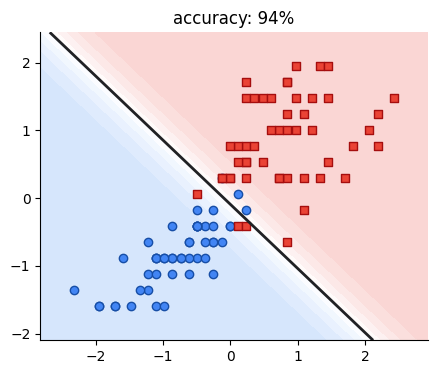

In [6]:
w, b, lr = np.zeros(2), 0.0, 0.5            # start knowing nothing
for step in range(301):
    p = neuron(X, w, b)                                          # 1. predict
    loss = -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))     # 2. how wrong? (log-loss)
    w -= lr * X.T @ (p - y) / len(y)                             # 3. step downhill: error × input
    b -= lr * np.mean(p - y)
    if step % 50 == 0:
        print(step, loss.round(3))

plot_boundary(lambda grid: neuron(grid, w, b), X, y)

✅ **Checkpoint:** the loss falls from 0.693 (a coin toss) and the plot reads **accuracy: 94%**, close to the best possible line (97%): the neuron minimises its loss, not its count of mistakes. That's chapter 5 of the talk in eight lines.

> 🧪 **Challenge 1.3 (bonus) · Rediscover a law of nature**
>
> Take away the bend and a neuron is just a straight line, $\hat{y} = wx + b$. Fit one to the planets (talk, slides 23–25) by minimising the **mean squared error**, $L = \text{mean}\big((\hat{y} - y)^2\big)$, whose slope is $2\,\text{mean}\big((\hat{y} - y)\,x\big)$. What slope $w$ do you find? Then try `lr = 0.8`.
>
> ```python
> a = np.array([0.387, 0.723, 1, 1.524, 5.204, 9.572, 19.164, 30.181])    # distance from the Sun (Earth = 1)
> T = np.array([0.241, 0.615, 1, 1.881, 11.859, 29.428, 83.760, 163.746])  # time for one orbit (years)
> x, t = np.log10(a), np.log10(T)
> ```

<details><summary><b>💡 Solution</b></summary>

```python
w, b, lr = 0.0, 0.0, 0.1
for step in range(500):
    err = w * x + b - t              # prediction minus truth
    w -= lr * 2 * np.mean(err * x)   # slope of the mean squared error
    b -= lr * 2 * np.mean(err)
print(w.round(3))
```

$w \approx 1.498$: $\log T = 1.5 \log a$, so $T^2 \propto a^3$. That's **Kepler's third law**, which took Kepler years of Tycho Brahe's observations (1619). With `lr = 0.8` every step overshoots further than the last and the fit explodes. Choosing the learning rate is one of the black arts of deep learning.

</details>

> 🔑 **Key points**
>
> - A neuron is a weighted vote plus a bias, then a bend: $\sigma(\mathbf{w}\cdot\mathbf{x} + b)$.
> - Weights tilt its decision line; the bias slides it.
> - Learning = measure the loss, step every weight a little downhill, repeat.

---
## Part 2 · A neural network

> ⏱️ **Teaching:** 10 min · **Exercises:** 5 min
>
> ❓ What does a whole layer compute? How do we find slopes for millions of weights? Why stack layers, and why bend?
>
> 🎯 Compute a layer as one matrix multiply · check backpropagation against PyTorch · train a network that can bend its decision line

### A layer is a matrix

Put four neurons side by side, all reading the same three inputs, and stack their weights as the rows of a matrix $W$. The whole layer is then **one matrix multiplication**: $\mathbf{a} = \sigma(W\mathbf{x} + \mathbf{b})$ (the right half of the figure above).

In [7]:
W = np.array([[ 1.2, -0.8,  0.5],   # row 1: our neuron from Part 1
              [-0.4,  0.9,  0.7],
              [ 0.3,  1.1, -1.0],
              [-0.9,  0.2,  0.6]])
b = np.array([-0.2, 0.1, 0.4, -0.3])
x = np.array([0.9, 0.2, 0.6])

sigmoid(W @ x + b).round(2)         # four neurons in one line

array([0.73, 0.58, 0.57, 0.33])

### Backpropagation: who is to blame?

To train many weights we need the slope of the loss with respect to *each* one. **Backpropagation** gets them all in one backward sweep using the chain rule: *multiply the local slopes along the path*. Here's the talk's tiny example: one input $x = 2$, one weight $w = 0.5$, a sigmoid, and a squared error against the right answer $y = 1$.

In [8]:
x, w, y = 2.0, 0.5, 1.0
p = sigmoid(w * x)                  # forward: z = 1.0, p = 0.731
loss = (p - y) ** 2                 # loss = 0.0723

dloss_dp, dp_dz, dz_dw = 2 * (p - y), p * (1 - p), x   # backward: each box's local slope
print(dloss_dp.round(3), dp_dz.round(3), dz_dw, (dloss_dp * dp_dz * dz_dw).round(4))

-0.538 0.197 2.0 -0.2115


### 🚀 Level up: let PyTorch do the calculus

Deriving slopes by hand doesn't scale. **PyTorch** records every operation on the way forward, then runs the chain rule backwards for you. This is *autograd*. Same numbers:

In [9]:
w = torch.tensor(0.5, requires_grad=True)     # a knob PyTorch should keep track of
loss = (torch.sigmoid(w * 2.0) - 1.0) ** 2    # the same forward pass
loss.backward()                               # backpropagation, automated
w.grad

tensor(-0.2115)

### When one straight line isn't enough

Two interleaved half-moons: no straight line can separate them. In PyTorch a layer of neurons is `nn.Linear` (a weight matrix plus biases), `nn.Sequential` chains layers, and `torch.optim` does the downhill steps. The training loop has four steps, and it's the same loop that trains Gemini.

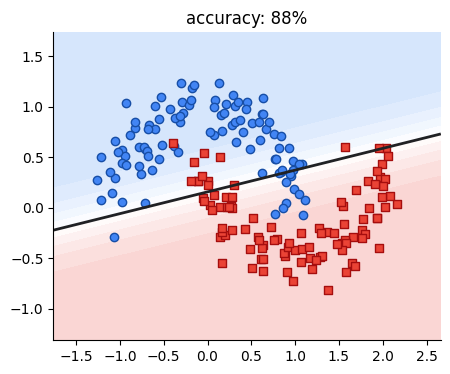

In [10]:
X, y = make_moons(200, noise=0.15, random_state=0)
X, y = torch.tensor(X, dtype=torch.float32), torch.tensor(y, dtype=torch.float32)

def fit(model, steps=1000):
    opt = torch.optim.Adam(model.parameters(), lr=0.05)   # a smarter way to roll downhill
    for step in range(steps):
        loss = F.binary_cross_entropy_with_logits(model(X).squeeze(1), y)   # 1. predict and measure
        opt.zero_grad()                                   # 2. forget the old slopes
        loss.backward()                                   # 3. backprop: a slope for every weight
        opt.step()                                        # 4. step downhill
    return model

plot_boundary(fit(nn.Linear(2, 1)), X, y)                 # one neuron draws one straight line

(`binary_cross_entropy_with_logits` is the same log-loss as in Part 1, with the sigmoid built in.) Now add a **hidden layer** of 16 neurons and a bend between the layers:

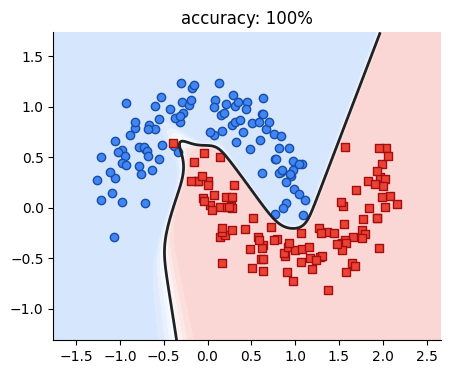

In [11]:
net = nn.Sequential(nn.Linear(2, 16), nn.Tanh(), nn.Linear(16, 1))   # 2 inputs → 16 neurons → bend → 1 output
plot_boundary(fit(net), X, y)

✅ **Checkpoint:** the boundary now curves between the moons (≈ 100%). Each layer stretches, shifts and **bends** the plane until a straight line can do the job: *deep learning = warp, warp, warp*.

> 🧪 **Challenge 2.1 · Why bend?**
>
> Swap `nn.Tanh()` for `nn.Identity()` (no bend at all) and re-run. What happens, and why?

<details><summary><b>💡 Solution</b></summary>

The boundary goes back to a straight line (about 88%, just like the single neuron). Without a bend, two layers collapse into one: $W_2(W_1\mathbf{x} + \mathbf{b}_1) + \mathbf{b}_2 = (W_2W_1)\mathbf{x} + (W_2\mathbf{b}_1 + \mathbf{b}_2)$, which is just another matrix. A hundred straight layers are still one straight layer. **The bend is what makes deep learning deep.** Try `nn.ReLU()` too, the bend that powered the 2012 boom.

</details>

> 🔑 **Key points**
>
> - A layer is one matrix multiply plus a bend: $\sigma(W\mathbf{x} + \mathbf{b})$.
> - Backpropagation is the chain rule; `loss.backward()` applies it to every weight at once.
> - Every model trains with the same loop: predict → loss → backward → step.
> - Without the bend, any stack of layers collapses into a single straight line.

---
## Part 3 · Attention

> ⏱️ **Teaching:** 7 min · **Exercises:** 3 min
>
> ❓ How can a network read a sentence when the meaning of a word depends on the others?
>
> 🎯 Turn words into vectors · write causal self-attention from scratch · check it against PyTorch's built-in version

### Words become vectors

Networks need numbers, so each token gets a list of numbers: one row of an **embedding table** that training will tune. Gemma 3 270M uses 640 numbers per token; we'll use 16. In PyTorch the table is `nn.Embedding`.

In [12]:
words = "the trophy did not fit in the suitcase because it was too big".split()
vocab = sorted(set(words))
ids = torch.tensor([vocab.index(w) for w in words])   # words → token IDs
embed = nn.Embedding(len(vocab), 16)                  # a lookup table: one row of 16 numbers per word
x = embed(ids)                                        # the sentence as a matrix
ids, x.shape

(tensor([ 8, 10,  2,  6,  3,  4,  8,  7,  0,  5, 11,  9,  1]),
 torch.Size([13, 16]))

### Let the words look at each other

What does *it* refer to, the trophy or the suitcase? With attention, every token asks a question and the tokens before it answer. Each token makes three vectors:

- a **query**: *what am I looking for?*
- a **key**: *what do I contain?*
- a **value**: *what will I pass on?*

Score every query against every key, turn the scores into weights with a softmax, and mix the values. A **causal mask** hides the future, so each token can only look back.

$$\text{Attention}(Q, K, V) = \text{softmax}\!\left(\frac{QK^\top}{\sqrt{d}} + \text{mask}\right)V$$

![The sentence 'The trophy did not fit in the suitcase because it was too big', with arcs from 'it' back to earlier words. In Gemma 3 (layer 9, head 2) 'it' sends 51% of its attention to 'trophy' and 8% to 'suitcase'; later words are masked. Below: three steps, score (query dot key over root d), softmax (weights that sum to 1), mix (weighted sum of values).](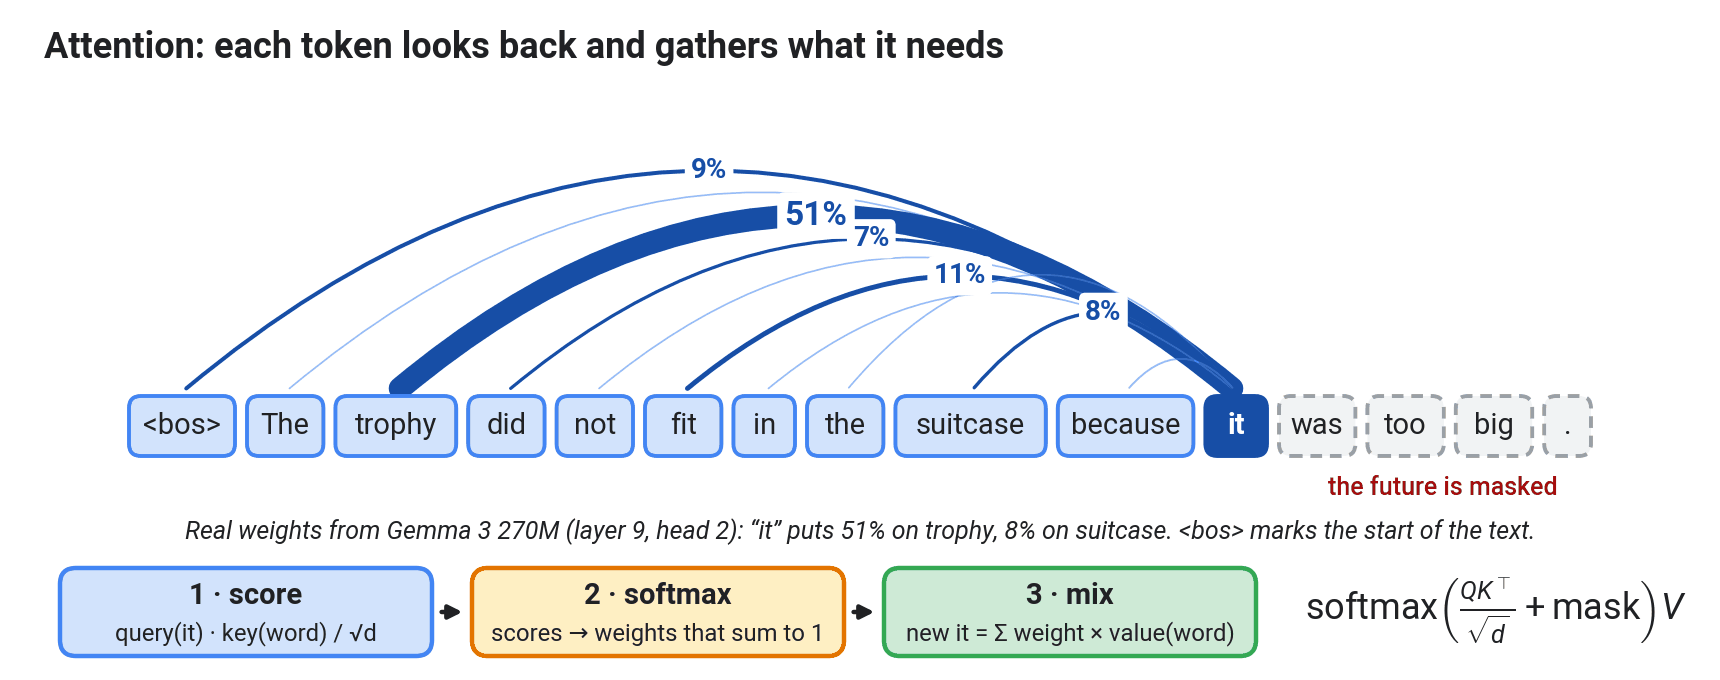)

*What a trained head does: real attention weights from Gemma 3, as shown in the talk.*

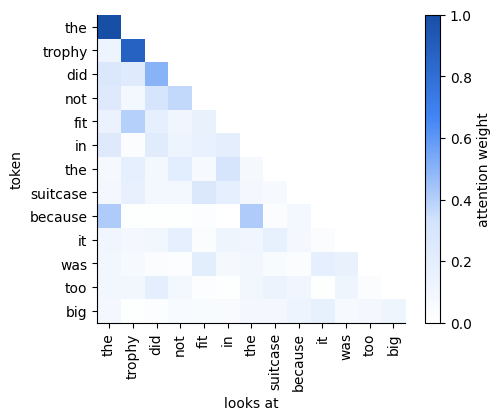

In [13]:
T, d = x.shape                                  # 13 tokens, 16 numbers each
Wq, Wk, Wv = torch.randn(3, d, d) / d**0.5      # three projections (random until trained)
q, k, v = x @ Wq, x @ Wk, x @ Wv                # what each token looks for, offers, and carries

scores = q @ k.T / d**0.5                       # how well each query matches each key
future = torch.ones(T, T).triu(1).bool()        # True above the diagonal: the future
weights = scores.masked_fill(future, float("-inf")).softmax(dim=-1)   # each row sums to 1
out = weights @ v                               # each token becomes a mix of the values it attends to

plot_attention(weights, words)

✅ **Checkpoint:** a triangle. Each word only looks backwards, and every row adds up to 1. Our projections are random, so *where* each word looks is random too; training is what tunes $W_q$, $W_k$ and $W_v$ until useful patterns like *it → trophy* appear.

### 🚀 Level up: the built-in version

PyTorch ships those six lines as one fused, fast function. Same answer:

In [14]:
fast = F.scaled_dot_product_attention(q, k, v, is_causal=True)
torch.allclose(out, fast, atol=1e-6)

True

Real Transformers run several attention **heads** side by side, each with its own $W_q$, $W_k$, $W_v$, so that different heads can track different relationships: the previous word, what *it* refers to, and so on. `nn.MultiheadAttention` packages that up, and we'll use it next.

> 🧪 **Challenge 3.1 · The temperature dial**
>
> Dividing the scores by $\sqrt{d}$ before the softmax works like a *temperature*. Re-plot with `scores * 10` (cold) and with `scores / 10` (hot). What happens to each row?

<details><summary><b>💡 Solution</b></summary>

```python
plot_attention((scores * 10).masked_fill(future, float("-inf")).softmax(dim=-1), words)
```

Cold (`* 10`): each row snaps to (almost) a single token, so each word stares at one other word. Hot (`/ 10`): the rows flatten out towards an even average of everything before. It's the same dial as the talk's temperature slider for "hi": low is predictable, high is adventurous. The $\sqrt{d}$ keeps the scores in a sensible range as vectors get longer.

</details>

> 🔑 **Key points**
>
> - Tokens become vectors through a learned lookup table (`nn.Embedding`).
> - Attention scores queries against keys, softmaxes the scores and mixes the values.
> - The causal mask lets each token look only backwards, which is what lets a model write left to right.
> - `F.scaled_dot_product_attention` is the same maths, fused and fast.

---
## Part 4 · A Transformer

> ⏱️ **Teaching:** 10 min · **Exercises:** 5 min
>
> ❓ How do embeddings, attention and neurons fit together? Can a tiny Transformer learn a real rule?
>
> 🎯 Build a Transformer block · train a 100,000-weight model to write DNA · generate one token at a time · look inside its attention

### The block: talk, then think

A Transformer repeats two moves:

1. **Attention**: tokens *talk*, sharing information (Part 3).
2. **MLP**: each token *thinks* on its own, with a small neural network (Part 2).

Each move *adds* its result to the token's vector (a **residual connection**), and a `LayerNorm` before each move keeps the numbers well scaled. Stack a few blocks, add token and position embeddings at the bottom and a layer that scores every possible next token at the top. That's GPT, Gemma and Gemini, at very different scales.

![Token IDs go into token plus position embeddings, then through two blocks. In each block the residual stream branches into Norm then masked multi-head attention, added back, then Norm then an MLP (Linear, GELU, Linear), added back. A final Norm and Linear layer give 5 scores, and a softmax turns them into next-token probabilities. Ours: 2 blocks, 4 heads, 64 numbers per token, about 0.1 million weights. Gemma 3 270M: 18 blocks, 4 heads, 640 numbers per token, 268 million weights.](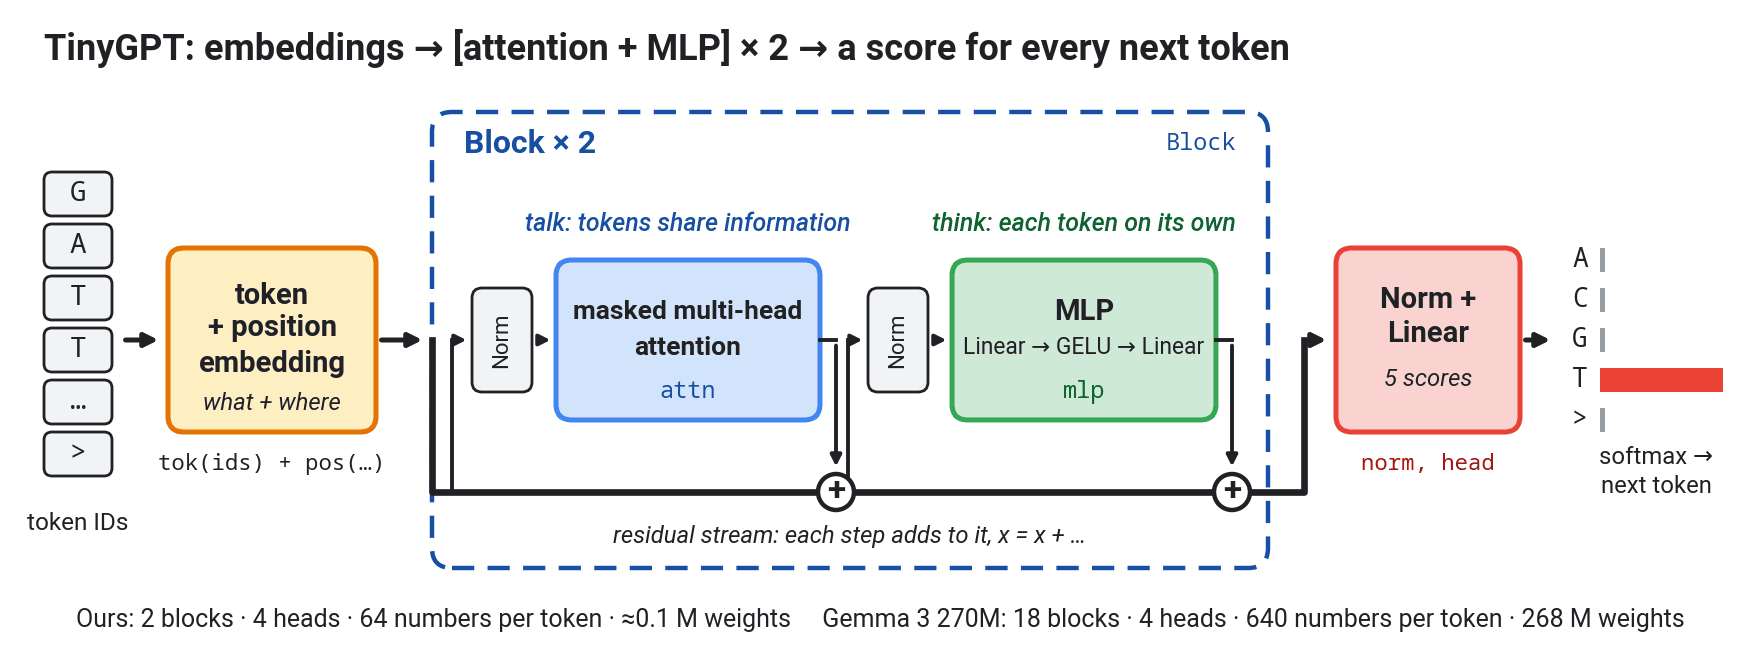)

*The model we're about to write, labelled with the names used in the code.*

In [15]:
class Block(nn.Module):
    def __init__(self, d, heads):
        super().__init__()
        self.norm1, self.norm2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, batch_first=True)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))

    def forward(self, x):
        T = x.size(1)
        future = torch.ones(T, T).triu(1).bool()            # the causal mask from Part 3
        h = self.norm1(x)
        a, self.weights = self.attn(h, h, h, attn_mask=future)   # keep the weights to look at later
        x = x + a                                           # 1. talk: tokens share information
        return x + self.mlp(self.norm2(x))                  # 2. think: each token on its own


class TinyGPT(nn.Module):
    def __init__(self, vocab, context, d=64, heads=4, layers=2):
        super().__init__()
        self.tok = nn.Embedding(vocab, d)                   # what each token is
        self.pos = nn.Embedding(context, d)                 # where each token is
        self.blocks = nn.Sequential(*[Block(d, heads) for _ in range(layers)])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Linear(d, vocab)                     # a score for every possible next token

    def forward(self, ids):
        x = self.tok(ids) + self.pos(torch.arange(ids.size(1)))
        return self.head(self.norm(self.blocks(x)))

### A job for it: DNA

DNA is double-stranded. A pairs with T, C pairs with G, and the partner strand runs the other way. Given a strand, our model must write its **reverse complement**, one base at a time:

`GATTACAGATTA>` → `TAATCTGTAATC`

That's next-token prediction, exactly like Gemma, but with a five-token vocabulary (`A C G T >`) and as much training data as we like. Numbering the bases A, C, G, T = 0, 1, 2, 3 makes the complement simply `3 - base`.

In [16]:
L = 12                                          # bases per strand

def batch(n=64):
    strand = torch.randint(0, 4, (n, L))        # random DNA (A, C, G, T = 0, 1, 2, 3)
    partner = (3 - strand).flip(1)              # complement (A↔T, C↔G), then reverse
    seq = torch.cat([strand, torch.full((n, 1), 4), partner], dim=1)   # token 4 is ">"
    return seq[:, :-1], seq[:, 1:]              # the inputs, and the next token at every position

def decode(ids):
    return "".join("ACGT>"[i] for i in ids)

x, y = batch(1)
print(decode(x[0]))
print(decode(y[0]))

ACCGCATGCTAC>GTAGCATGCGG
CCGCATGCTAC>GTAGCATGCGGT


The second line is the first shifted by one: at every position, the target is simply *the next token*. The first half is random, so we only grade the model on the answer after `>`. The loss is the **cross-entropy**: how surprised the model was by the true next token.

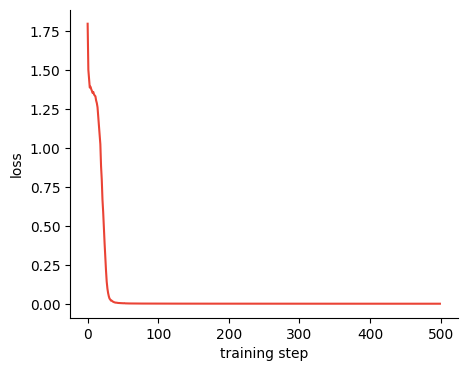

In [17]:
model = TinyGPT(vocab=5, context=2 * L)
opt = torch.optim.AdamW(model.parameters(), lr=3e-3)
losses = []
for step in range(500):
    x, y = batch()
    logits = model(x)                                                         # (strands, positions, 5 scores)
    loss = F.cross_entropy(logits[:, L:].flatten(0, 1), y[:, L:].flatten())  # grade the answer half only
    opt.zero_grad()
    loss.backward()
    opt.step()
    losses.append(loss.item())

plt.plot(losses, color=RED)
plt.xlabel("training step")
plt.ylabel("loss")
plt.show()

Notice the brief plateau near 1.39. That's $\ln 4$, the surprise of a fair four-way guess: the model has learned that a base comes next, but not which one. Then it discovers the rule and the loss collapses.

### Write one token, append it, repeat

Generation is a loop: turn the last position's scores into probabilities with a softmax (divided by a **temperature**), roll a weighted die, append the token and go again. That's how Gemma wrote *"Hi there! How can I help you today?"* in the talk. Our default temperature, 0.01, is so low that the die almost always lands on the top token.

In [18]:
@torch.no_grad()
def generate(ids, n, temperature=0.01):
    for _ in range(n):
        probs = (model(ids)[:, -1] / temperature).softmax(dim=-1)   # next-token probabilities
        ids = torch.cat([ids, torch.multinomial(probs, 1)], dim=1)  # roll the die, append, repeat
    return ids

def encode(text):
    return torch.tensor([["ACGT>".index(c) for c in text]])

decode(generate(encode("GATTACAGATTA>"), L)[0])

'GATTACAGATTA>TAATCTGTAATC'

Did it just memorise? It trained on 32,000 strands (500 steps × 64) out of 16.7 million possible ones, so let's test it on 1,000 fresh ones:

In [19]:
x, y = batch(1000)
out = generate(x[:, :L + 1], L)                       # prompt: each strand plus ">"
(out[:, L + 1:] == y[:, L:]).all(dim=1).float().mean()  # fraction written perfectly

tensor(1.)

✅ **Checkpoint:** `tensor(1.)`: all 1,000 new strands come out perfectly reverse-complemented. It learned the *rule*, not a list of answers.

### Look inside

How does it find the right base? Plot where each token looks in the first block (averaged over its four heads):

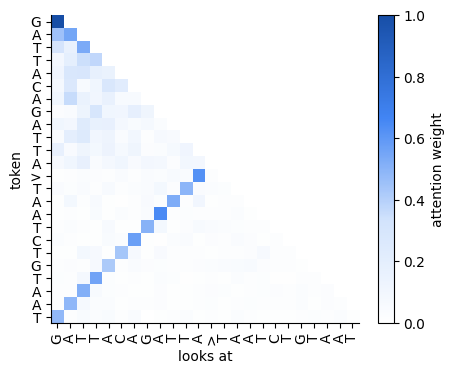

In [20]:
ids = generate(encode("GATTACAGATTA>"), L)[:, :-1]   # strand + ">" + answer
model(ids)                                           # one more pass, so each Block records its attention
plot_attention(model.blocks[0].weights[0], list(decode(ids[0])))

After the `>`, the attention forms an **anti-diagonal**: each output base looks straight at its mirror-image base in the input, which is exactly the base it needs to complement. Nobody programmed this wiring; gradient descent found it. That's the talk's point about attention: *the wiring is computed from the data*.

> 🧪 **Challenge 4.1 · Temperature as a mutation rate**
>
> Generate the 1,000 test strands with `temperature=3`. What fraction of bases come out wrong?

<details><summary><b>💡 Solution</b></summary>

```python
out = generate(x[:, :L + 1], L, temperature=3)
(out[:, L + 1:] != y[:, L:]).float().mean()
```

Roughly 1 base in 9 mutates (11–12%, and about a third at `temperature=5`). Low temperature gives a faithful copy; high temperature makes the model adventurous, and here adventure means mutations. Prediction is not truth.

</details>

> 🧪 **Challenge 4.2 · Where am I?**
>
> Delete `+ self.pos(torch.arange(ids.size(1)))` from `TinyGPT.forward`, then re-run the model, training and test cells. What breaks, and why?

<details><summary><b>💡 Solution</b></summary>

Far fewer strands come out perfect: typically 25–40%, down from 100%. Attention on its own is *order-blind*: without position embeddings a token can't tell which base is its mirror image. (The causal mask still leaks a little order information, so it's not hopeless.) Position embeddings tell every token *where* it is.

</details>

> 🧪 **Challenge 4.3 (bonus) · One last level up**
>
> PyTorch even ships the whole block. Rewrite `TinyGPT` with `nn.TransformerEncoderLayer` and train it again.

<details><summary><b>💡 Solution</b></summary>

```python
class TinyGPT(nn.Module):
    def __init__(self, vocab, context, d=64, heads=4, layers=2):
        super().__init__()
        self.tok, self.pos = nn.Embedding(vocab, d), nn.Embedding(context, d)
        block = nn.TransformerEncoderLayer(d, heads, 4 * d, dropout=0.0, activation="gelu",
                                           batch_first=True, norm_first=True)
        self.blocks = nn.TransformerEncoder(block, layers, enable_nested_tensor=False)
        self.norm, self.head = nn.LayerNorm(d), nn.Linear(d, vocab)

    def forward(self, ids):
        T = ids.size(1)
        x = self.tok(ids) + self.pos(torch.arange(T))
        mask = nn.Transformer.generate_square_subsequent_mask(T)
        return self.head(self.norm(self.blocks(x, mask=mask, is_causal=True)))
```

Same 102,277 weights, same 100% (the attention plot needs our own `Block`, which keeps its weights). Libraries such as KerasHub and Hugging Face Transformers go one step further and load whole pre-trained models, like Gemma, in a line.

</details>

### Then do it at an absurd scale

How big is our model?

In [21]:
sum(p.numel() for p in model.parameters())

102277

| Model | Weights | Blocks × heads | Numbers per token |
|:--|--:|:--|--:|
| Our `TinyGPT` | 102,277 | 2 × 4 | 64 |
| Gemma 3 270M | 268,098,176 | 18 × 4 | 640 |
| GPT-3 (2020) | 175,000,000,000 | 96 × 96 | 12,288 |

Same blocks, same training loop. Gemma 3 270M is about 2,600 times bigger than ours, and it is a *small* model.

> 🔑 **Key points**
>
> - A Transformer block = attention (tokens talk) + MLP (each token thinks), each added back through a residual connection.
> - Embeddings say *what* each token is; position embeddings say *where* it is.
> - A language model predicts the next token; generation repeats predict → sample → append.
> - Attention patterns are learned wiring, and you can look at them.

---
## Wrap-up: the whole story in six equations

| # | Idea | Equation | Where you wrote it |
|:--|:--|:--|:--|
| 1 | A layer: multiply, shift, bend | $\sigma(W\mathbf{x} + \mathbf{b})$ | `sigmoid(W @ x + b)` → `nn.Linear` + `nn.Tanh` |
| 2 | Loss: measure how wrong | squared error, log-loss, cross-entropy | `-np.mean(y * np.log(p) + …)` → `F.cross_entropy` |
| 3 | Gradient descent: roll downhill | $w \leftarrow w - \eta\,\partial L / \partial w$ | `w -= lr * …` → `opt.step()` |
| 4 | Backpropagation: blame flows back | chain rule | `dloss_dp * dp_dz * dz_dw` → `loss.backward()` |
| 5 | Self-attention: words look at words | $\text{softmax}(QK^\top/\sqrt{d})\,V$ | `weights @ v` → `nn.MultiheadAttention` |
| 6 | Softmax and temperature: scores → choices | $\text{softmax}(\mathbf{z}/T)$ | `(logits / temperature).softmax(dim=-1)` |

> **Multiply, bend, repeat. Measure the error, roll downhill, repeat. Then do it at an absurd scale.**

> 🔑 **Key points**
>
> - Every model today is built from the same neuron: a weighted vote and a bend.
> - Training is always the same loop: predict, measure the loss, backpropagate, step downhill.
> - Attention lets tokens share information, with wiring learned from the data.
> - Write each idea once from scratch, then use the library: the ideas don't change, only the scale does.

### Keep exploring

- 3Blue1Brown, [*Neural networks*](https://www.3blue1brown.com/topics/neural-networks): the visual intuition behind every part of this notebook.
- Andrej Karpathy, [*Let's build GPT: from scratch, in code, spelled out*](https://www.youtube.com/watch?v=kCc8FmEb1nY) and [nanoGPT](https://github.com/karpathy/nanoGPT).
- Brendan Bycroft, [*LLM Visualization*](https://bbycroft.net/llm), and Polo Club's [*Transformer Explainer*](https://poloclub.github.io/transformer-explainer/): a whole GPT in 3D.
- Jay Alammar, [*The Illustrated Transformer*](https://jalammar.github.io/illustrated-transformer/), and Vaswani et al. (2017), [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762).
- The full 90-minute workshop in [`../workshop/`](../workshop/): tokenizers, real Gemma 3 weights and attention heads, Kepler, LoRA and a lab playbook.
- [Software Carpentry](https://software-carpentry.org/) and the [CAITG AI Winter School](https://gdgaiforscience.github.io/CAITG-WinterSchool/).